# Processamento de Sinais Multimédia (PSM)
**Licenciatura em Engenharia Informática e Multimédia (LEIM) — ISEL**  
**Ano Letivo:** 2025/2026 | **Semestre:** Verão  

---

# Trabalho Prático 1 (TP1)
### Processador de Áudio Digital: Equalizador FIR Multi-Banda e Reverberador Sintético de Schroeder

* **Data de Lançamento:** Semana 3
* **Checkpoint de Validação:** Semana 5
* **Data de Entrega Final:** Semana 7

---

## 1. Contexto e Objetivos

O processamento digital de áudio assenta frequentemente na combinação de filtros que atuam no **domínio da frequência** (modificando o conteúdo espectral/timbre) e no **domínio do tempo** (simulando a propagação e reflexões acústicas no espaço).

O objetivo deste trabalho é projetar e implementar um **processador de áudio digital integrado em Python** composto por dois blocos fundamentais:

1. **Equalizador Grafico Multi-Banda (FIR):** Utilização da técnica de janelamento (`scipy.signal.firwin`) para controlo independente de frequências graves, médias e agudas.
2. **Reverberador Sintético de Schroeder (IIR):** Uma rede de filtros *Comb* IIR dispostos em paralelo, seguidos de filtros *All-Pass* IIR em série, simulando a acústica de um espaço fechado.

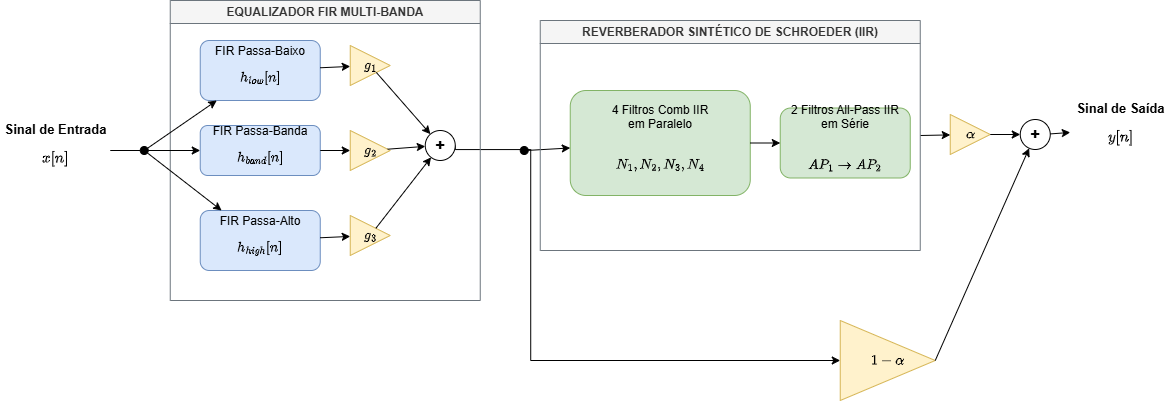

---

## 2. Requisitos de Implementação

### Parte A — Equalizador FIR Multi-Banda (`firwin`)

A unidade de equalização deve processar o sinal de entrada $x[n]$ com frequência de amostragem $F_s = 44100\text{ Hz}$ dividindo-o em 3 bandas de frequência:

1. **Especificação das Bandas:**
   * **Banda 1 (Graves - Passa-Baixo):** Frequência de corte $f_{c1} = 300\text{ Hz}$.
   * **Banda 2 (Médios - Passa-Banda):** Frequências de corte $f_{c1} = 300\text{ Hz}$ e $f_{c2} = 3000\text{ Hz}$.
   * **Banda 3 (Agudos - Passa-Alto):** Frequência de corte $f_{c2} = 3000\text{ Hz}$.
2. **Dimensionamento dos Filtros:**
   * Os 3 filtros devem ser projetados utilizando a função `scipy.signal.firwin` com uma ordem $M = 101$ (comprimento da resposta ao impulso $N_{taps} = 101$) e janela de Hamming.
3. **Equalização:**
   * O utilizador especifica três ganhos lineares $g_1, g_2, g_3 \ge 0$.
   * A saída do equalizador $x_{eq}[n]$ é a combinação linear das saídas dos 3 filtros:
     $$x_{eq}[n] = g_1 \cdot y_{\text{graves}}[n] + g_2 \cdot y_{\text{médios}}[n] + g_3 \cdot y_{\text{agudos}}[n]$$

---

### Parte B — Reverberador Sintético de Schroeder (IIR)

O sinal equalizado $x_{eq}[n]$ é alimentado à estrutura de reverberação de Schroeder:

1. **Banco de Filtros Comb IIR em Paralelo (4 ramos):**
   * Cada filtro *Comb* é definido pela equação às diferenças:
     $$y_{c,k}[n] = x_{eq}[n] + g_k \cdot y_{c,k}[n - N_k]$$
   * Os atrasos $N_k$ (em número de amostras) devem ser calculados a partir de tempos em milissegundos escolhidos como **primos entre si** (sugestão: $T_1 = 29.7\text{ ms}$, $T_2 = 37.1\text{ ms}$, $T_3 = 41.1\text{ ms}$, $T_4 = 43.7\text{ ms}$) para minimizar coloração espetral periódica.
   * Os ganhos de realimentação devem estar no intervalo $g_k \in [0.70, 0.80]$.
   * As saídas dos 4 filtros *Comb* são somadas: $x_{ap}[n] = \sum_{k=1}^4 y_{c,k}[n]$.

2. **Cascata de Filtros All-Pass IIR em Série (2 andares):**
   * A soma dos filtros *Comb* passa sequencialmente por 2 filtros *All-Pass* IIR.
   * A equação às diferenças de cada andar *All-Pass* é dada por:
     $$y_{ap}[n] = -a \cdot x_{in}[n] + x_{in}[n - N_{ap}] + a \cdot y_{ap}[n - N_{ap}]$$
   * Parâmetros recomendados: $a = 0.7$ e atrasos curtos ($T_{ap1} = 5.0\text{ ms}$, $T_{ap2} = 1.7\text{ ms}$).

3. **Mistura Dry/Wet:**
   * O sinal final do sistema $y[n]$ deve permitir o controlo da proporção de som direto (seco) e som reverberado (húmido) via um parâmetro $\alpha \in [0, 1]$:
     $$y[n] = (1 - \alpha) \cdot x_{eq}[n] + \alpha \cdot y_{\text{reverb}}[n]$$
   * O sinal final deve ser normalizado para evitar *clipping* (amplitude pico $\le 1.0$).

---

## 3. Tarefas de Análise e Visualização

No relatório/notebook a entregar, o grupo deve apresentar obrigatoriamente:

1. **Análise Frequencial do Equalizador:**
   * Traçar os gráficos da resposta em frequência em magnitude ($\vert{}H(e^{j\omega})\vert{}$ em dB) dos 3 filtros FIR individuais utilizando `scipy.signal.freqz`.
   * Mostrar a resposta em frequência combinada do equalizador para 2 configurações distintas de ganhos (ex.: *Bass Boost* $[2.0, 1.0, 0.5]$ e *Treble Boost* $[0.5, 1.0, 2.0]$).
2. **Análise do Reverberador:**
   * Obter e plotar a **Resposta ao Impulso $h[n]$** da estrutura de Schroeder completa aplicada a um impulso unitário $x[n] = \delta[n]$.
   * Comentar a densidade de impulsos ao longo do tempo e a taxa de decaimento da "cauda" de reverberação.
3. **Teste Prático de Áudio:**
   * Aplicar o processador completo a pelo menos dois ficheiros de áudio distintos:
     1. Um sinal de voz/locução seco (*dry speech*);
     2. Um sinal percussivo ou instrumental seco (ex.: bateria ou som de guitarra).
   * Disponibilizar os leitores de áudio no notebook (`IPython.display.Audio`) para comparação do sinal original vs. processado.


Atrasos Comb: [1310, 1636, 1813, 1927] amostras
Atrasos All-Pass: [220, 75] amostras


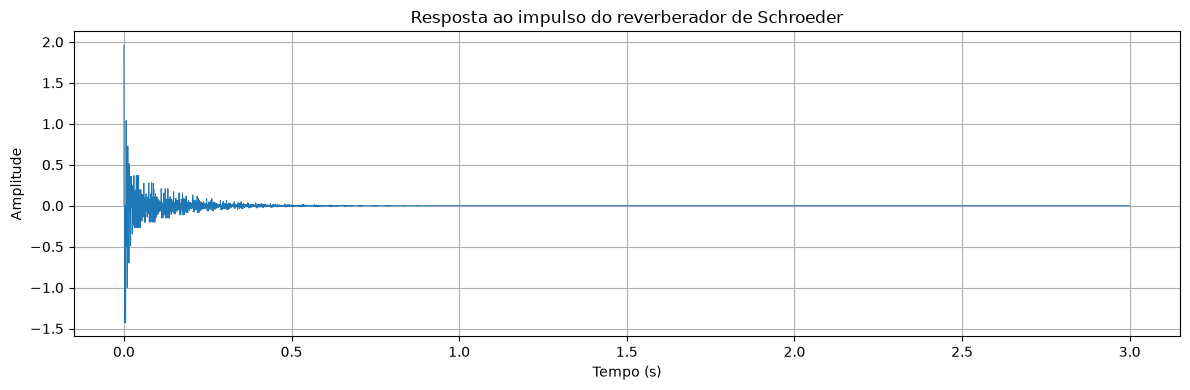

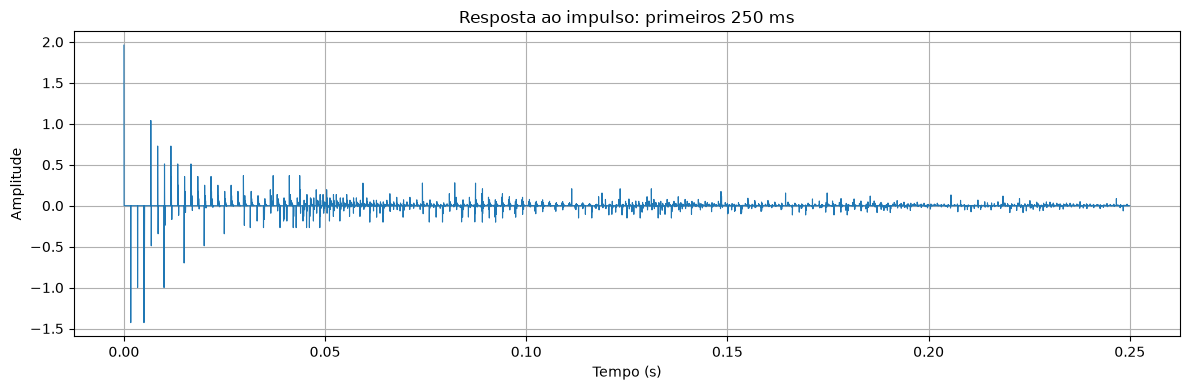

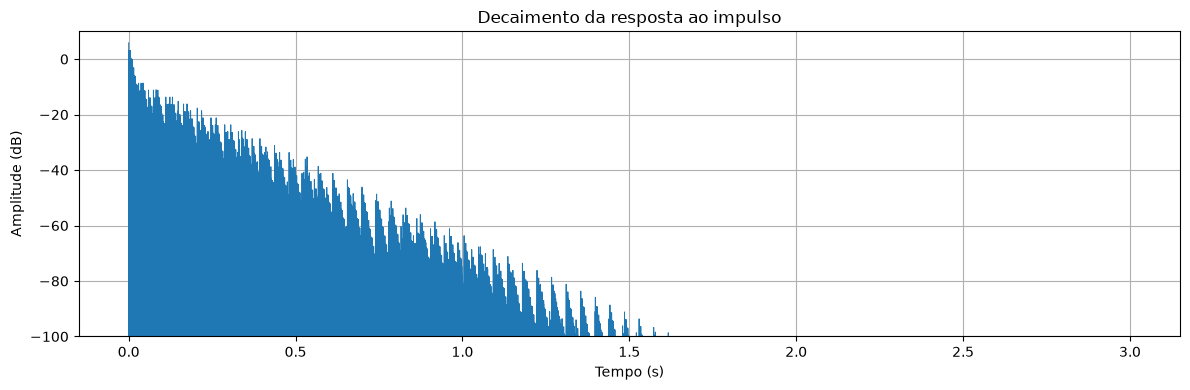

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter
from IPython.display import Audio, display

Fs = 44100  # Frequência de amostragem, em Hz
duracao = 3.0
N_amostras = int(Fs * duracao)

#Criar o impulso unitario x[n] = delta[n]
x = np.zeros(N_amostras)
x[0] = 1.0

#Parametros dos quatro filtros Comb
tempos_comb_ms = [29.7, 37.1, 41.1, 43.7]
ganhos_comb = [0.75, 0.75, 0.75, 0.75]

# Converter os atrasos de milissegundos para amostras
atrasos_comb = [
    round(tempo * Fs / 1000)
    for tempo in tempos_comb_ms
]

#Banco de quatro filtros Comb em paralelo
saidas_comb = []

for atraso, ganho in zip(atrasos_comb, ganhos_comb):
    # Numerador: 1
    b = np.array([1.0])

    # Denominador: 1 - ganho * z^(-atraso)
    a = np.zeros(atraso + 1)
    a[0] = 1.0
    a[atraso] = -ganho

    # Filtrar o impulso
    y_comb = lfilter(b, a, x)
    saidas_comb.append(y_comb)

# Somar as quatro saidas Comb
x_ap = np.sum(saidas_comb, axis=0)

#Parametros dos filtros All-Pass
ganho_ap = 0.7
tempos_ap_ms = [5.0, 1.7]

atrasos_ap = [
    round(tempo * Fs / 1000)
    for tempo in tempos_ap_ms
]

#Aplicar os dois filtros All-Pass em serie
y_reverb = x_ap.copy()

for atraso in atrasos_ap:
    # Numerador: -a + z^(-N)
    b = np.zeros(atraso + 1)
    b[0] = -ganho_ap
    b[atraso] = 1.0

    # Denominador: 1 - a * z^(-N)
    a = np.zeros(atraso + 1)
    a[0] = 1.0
    a[atraso] = -ganho_ap

    y_reverb = lfilter(b, a, y_reverb)

#A resposta ao impulso do sistema completo
h = y_reverb

#Eixo temporal em segundos
tempo = np.arange(N_amostras) / Fs

#Mostrar os atrasos efetivamente utilizados
print("Atrasos Comb:", atrasos_comb, "amostras")
print("Atrasos All-Pass:", atrasos_ap, "amostras")

#Grafico da resposta ao impulso completa
plt.figure(figsize=(12, 4))
plt.plot(tempo, h, linewidth=0.7)
plt.title("Resposta ao impulso do reverberador de Schroeder")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()

#Ampliacao dos primeiros 250 ms
plt.figure(figsize=(12, 4))
limite = int(0.250 * Fs)
plt.plot(tempo[:limite], h[:limite], linewidth=0.8)
plt.title("Resposta ao impulso: primeiros 250 ms")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()

#Grafico da amplitude em decibeis
amplitude_db = 20 * np.log10(np.maximum(np.abs(h), 1e-8))

plt.figure(figsize=(12, 4))
plt.plot(tempo, amplitude_db, linewidth=0.7)
plt.title("Decaimento da resposta ao impulso")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude (dB)")
plt.ylim(-100, 10)
plt.grid(True)
plt.tight_layout()
plt.show()


In [2]:
from scipy.io import wavfile
from scipy.signal import resample_poly
from math import gcd


def carregar_audio(caminho):
    # Ler o ficheiro WAV
    Fs_original, audio = wavfile.read(caminho)

    # Converter o sinal para float
    if np.issubdtype(audio.dtype, np.integer):
        info = np.iinfo(audio.dtype)

        if np.issubdtype(audio.dtype, np.unsignedinteger):
            meio = (info.max + 1) / 2
            audio = (audio.astype(np.float64) - meio) / meio
        else:
            escala = max(abs(info.min), info.max)
            audio = audio.astype(np.float64) / escala
    else:
        audio = audio.astype(np.float64)

    # Converter estéreo para mono, se necessário
    if audio.ndim == 2:
        audio = np.mean(audio, axis=1)

    # Converter para a frequência de amostragem do trabalho
    if Fs_original != Fs:
        divisor = gcd(Fs, Fs_original)

        audio = resample_poly(
            audio,
            Fs // divisor,
            Fs_original // divisor
        )

    # Evitar amplitudes superiores a 1 na entrada
    pico = np.max(np.abs(audio))

    if pico > 1.0:
        audio = audio / pico

    return audio


def aplicar_reverberador(audio):
    # Banco de filtros Comb em paralelo
    saidas_comb = []

    for atraso, ganho in zip(atrasos_comb, ganhos_comb):
        b = np.array([1.0])

        a = np.zeros(atraso + 1)
        a[0] = 1.0
        a[atraso] = -ganho

        y_comb = lfilter(b, a, audio)
        saidas_comb.append(y_comb)

    # Somar as quatro saídas Comb
    sinal_ap = np.sum(saidas_comb, axis=0)

    # Aplicar os dois filtros All-Pass em série
    y_reverb = sinal_ap.copy()

    for atraso in atrasos_ap:
        b = np.zeros(atraso + 1)
        b[0] = -ganho_ap
        b[atraso] = 1.0

        a = np.zeros(atraso + 1)
        a[0] = 1.0
        a[atraso] = -ganho_ap

        y_reverb = lfilter(b, a, y_reverb)

    return y_reverb


# 1. Definir os caminhos dos ficheiros
ficheiro_voz = "audio/voz_seca.wav"
ficheiro_instrumento = "audio/instrumento_seco.wav"

# 2. Definir a mistura Dry/Wet
alpha = 0.35

def processar_ficheiro(caminho):
    # Carregar o áudio
    audio_original = carregar_audio(caminho)

    # Aplicar o reverberador de Schroeder
    audio_reverb = aplicar_reverberador(audio_original)

    # Misturar o sinal seco com o reverberado
    audio_processado = (
        (1 - alpha) * audio_original
        + alpha * audio_reverb
    )

    # Aplicar a mesma escala aos dois sinais, se necessário
    pico_comum = max(
        np.max(np.abs(audio_original)),
        np.max(np.abs(audio_processado))
    )

    escala = max(1.0, pico_comum)

    audio_original = audio_original / escala
    audio_processado = audio_processado / escala

    return audio_original, audio_processado

# 3. Processar os dois ficheiros
voz_original, voz_processada = processar_ficheiro(ficheiro_voz)

instrumento_original, instrumento_processado = processar_ficheiro(
    ficheiro_instrumento
)

print("Os dois ficheiros foram processados com sucesso.")


print("VOZ — Original (Dry)")
display(Audio(voz_original, rate=Fs, normalize=False))

print("VOZ — Processada (Dry/Wet)")
display(Audio(voz_processada, rate=Fs, normalize=False))


print("INSTRUMENTO — Original (Dry)")
display(Audio(instrumento_original, rate=Fs, normalize=False))

print("INSTRUMENTO — Processado (Dry/Wet)")
display(Audio(instrumento_processado, rate=Fs, normalize=False))


C:\Users\HP\AppData\Local\Temp\ipykernel_29720\2086167504.py:8: WavFileWarning: Chunk (non-data) not understood, skipping it.
  Fs_original, audio = wavfile.read(caminho)


Os dois ficheiros foram processados com sucesso.
VOZ — Original (Dry)


VOZ — Processada (Dry/Wet)


INSTRUMENTO — Original (Dry)


INSTRUMENTO — Processado (Dry/Wet)


## 4. Critérios de Avaliação

A avaliação do TP1 será efetuada com base na discussão, demonstração prática, explicação do código desenvolvido e no rigor da análise apresentada no Jupyter Notebook. Não basta apresentar o código e os resultados é necessário explica-los e relaciona-los com a teoria dada nas aulas. A tabela seguinte é indicativa dos pesos relativos que vão ser avaliados:

| Componente | Descrição e Aspetos Avaliados | Cotação |
| :--- | :--- | :---: |
| **Equalizador FIR Multi-Banda** | • Projeto correto dos filtros (Passa-Baixo, Passa-Banda e Passa-Alto) usando `scipy.signal.firwin`.<br>• Implementação correta da combinação linear ponderada pelos ganhos ($g_1, g_2, g_3$) e normalização do sinal para prevenção de *clipping* <br>• Análise da resposta em frequência em magnitude ($\vert{}H(e^{j\omega})\vert{}$) individual e combinada via `scipy.signal.freqz` e se necessário no domínio do tempo usando sinusóides. | **30%** (6.0 val) |
| **Reverberador Sintético de Schroeder (IIR)** | • Implementação correta do banco de 4 filtros *Comb* IIR em paralelo e da cascata de 2 filtros *All-Pass* IIR em série.<br>• Escolha adequada dos tempos de atraso $N_k$ e ganhos de realimentação $g_k$ para evitar ressonâncias metálicas.<br>• Implementação do controlo da proporção *Dry/Wet* ($\alpha$) e normalização do sinal para prevenção de *clipping*. | **35%** (7.0 val) |
| **Análise da Resposta ao Impulso** | • Extração experimental e representação gráfica clara da resposta ao impulso $h[n]$ do sistema completo ($x[n] = \delta[n]$).<br>• Discussão crítica sobre o aumento da densidade de impulsos ao longo do tempo e a taxa de decaimento da "cauda" de reverberação. | **15%** (3.0 val) |
| **Testes e Demonstração em Áudio Real** | • Aplicação do processador completo a pelo menos dois sinais de áudio com características distintas (voz/locução e sinal percussivo/instrumental).<br>• Integração de leitores de áudio funcionais no notebook (`IPython.display.Audio`) e ausência de distorção ou artefatos indesejados. | **10%** (2.0 val) |
| **Qualidade do Código e Relatório** | • Organização, estrutura e documentação do Jupyter Notebook (clareza na divisão de módulos e comentários ao código).<br>• Rigor científico no uso da notação de sinais e sistemas, legibilidade dos gráficos (eixos devidamente identificados e unidades corretas) e clareza nas respostas teóricas. | **10%** (2.0 val) |

> **Nota:** Todos os trabalhos serão sujeitos a uma validação e discussão prática presencial durante as aulas de laboratório da Semana 7.

## 6. Regras e Calendarização de Entrega

1. **Constituição dos Grupos:**
   * O trabalho deve ser realizado em grupos de **2/3 alunos** inscritos na Unidade Curricular de Processamento de Sinais Multimédia (PSM).
   * Grupos serão definidos na semana 3 (ou 4)
   * Casos excecionais de trabalhos individuais devem ser previamente autorizados pelo docente.

2. **Formato e Submissão:**
   * A submissão deve ser efetuada até às **23:59 da data limite** através da plataforma Moodle da UC na atividade associada a cada turma.
   * Deve ser submetido um único ficheiro comprimido no formato `.zip` com a seguinte convenção de nome: `PSM_202526_TP1_GrupoXX.zip`.
   * Conteúdo obrigatório do ficheiro `.zip`:
     * Ficheiro Jupyter Notebook (`.ipynb`) com todo o código executado e os gráficos gerados.
     * Pasta `audio/` contendo os ficheiros `.wav` de teste (originais e resultantes do processamento).

3. **Datas Importantes:**
   * **Lançamento do TP1:** Semana 3
   * **Checkpoint / Validação Intermédia:** Aula de Laboratório da Semana 5 *(apresentação do equalizador FIR a funcionar e da resposta ao impulso preliminar do filtro Comb)*.
   * **Data Limite de Submissão:** Domingo da Semana 7 às 23:59.
   * **Discussões e Demonstração Prática:** Aulas laboratoriais da Semana 7.

4. **Integridade Académica e Discussão:**
   * A nota final do trabalho fica condicionada à **discussão oral presencial** e demonstração do protótipo em laboratório.
   * A classificação é individual, podendo ser atribuídas notas distintas a elementos do mesmo grupo consoante o domínio demonstrado durante a discussão.
   * Cópias parciais ou integrais de código entre grupos ou de fontes externas não citadas resultarão na anulação imediata do trabalho para todos os intervenientes envolvidos.